# Step 5: Forecast

Arps decline fits per field, ramp-up profiles for young fields, summed to a national liquids forecast for 2026–2028.

Starting with the field that matters most: Johan Sverdrup (about a third of national liquids).

In [29]:
from getpass import getpass

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import StrMethodFormatter
from scipy.optimize import curve_fit
from sqlalchemy import URL, create_engine, text

# Connect straight to the project database; the password is asked for, never stored
db_url = URL.create(
    "mysql+pymysql",
    username="root",
    password=getpass("MySQL root password: "),
    host="localhost",
    port=3306,
    database="norway_forecast",
)
db = create_engine(db_url)

# Monthly liquids rate per field, dates read as real dates
monthly = pd.read_sql(
    text("SELECT field_name, production_month, liquids_kbd, month_status FROM silver_field_production_rates"),
    db,
    parse_dates=["production_month"],
)
print(f"Loaded {len(monthly):,} field-months, latest month {monthly['production_month'].max():%Y-%m}")

Loaded 28,455 field-months, latest month 2026-07


In [30]:
def months_between(start, dates):
    """Whole months from `start` to each date in `dates` (0 for the start month itself)."""
    start = pd.Timestamp(start)
    return (dates.year - start.year) * 12 + (dates.month - start.month)


def arps_rate(t_months, qi, di, b):
    """Arps hyperbolic decline: rate after t months.
    qi = rate at t = 0 (kb/d), di = initial nominal decline (per month), b = hyperbolic exponent."""
    return qi / (1 + b * di * t_months) ** (1 / b)


def fit_arps(rates, decline_start, b=None):
    """Fit Arps to monthly rates (index = month) from decline_start on. Returns a dict of results.
    If b is given it is held fixed and only qi and di are fitted; otherwise b is fitted too."""
    t = months_between(decline_start, rates.index).to_numpy()
    q = rates.to_numpy()
    if b is None:
        (qi, di, b), _ = curve_fit(
            arps_rate, t, q,
            p0=[q[0], 0.01, 0.5],                     # starting guess for the solver
            bounds=([0, 0, 0.01], [np.inf, 1, 1]),    # b between 0.01 (~exponential) and 1 (harmonic)
        )
    else:
        (qi, di), _ = curve_fit(
            lambda t, qi, di: arps_rate(t, qi, di, b), t, q,
            p0=[q[0], 0.01],
            bounds=([0, 0], [np.inf, 1]),
        )
    fitted = arps_rate(t, qi, di, b)
    r_squared = 1 - ((q - fitted) ** 2).sum() / ((q - q.mean()) ** 2).sum()
    return {
        "decline_start": decline_start,
        "qi": qi,
        "di": di,
        "b": b,
        "r_squared": r_squared,
        "n_months": len(q),
        "annual_decline_pct": (1 - arps_rate(12, qi, di, b) / qi) * 100,
    }


def arps_forecast(fit, months):
    """Rates from a fit_arps result for the given months (DatetimeIndex)."""
    t = months_between(fit["decline_start"], months).to_numpy()
    return pd.Series(arps_rate(t, fit["qi"], fit["di"], fit["b"]), index=months)

In [31]:
# Engineering judgement (Sverdrup): Phase 2 plateau from Mar 2023. Annual averages
# 725 (2023), 728 (2024), 704 (2025), 658 kb/d (Jan-Jul 2026): slow decline began in 2024-25.
# Monthly dips are turnarounds / facility outages and stay in the data as noise.
# A fit from Dec 2025 only (17%/yr) was judged too aggressive.
# The cases differ in decline start (mainly sets Di) and b.
SVERDRUP_CASES = {
    "low":  {"decline_start": "2025-01-01", "b": 0.01},   # latest start, ~exponential
    "base": {"decline_start": "2024-07-01", "b": 0.5},
    "high": {"decline_start": "2024-01-01", "b": 1.0},    # earliest start, harmonic
}

sverdrup = (
    monthly[monthly["field_name"] == "JOHAN SVERDRUP"]
    .set_index("production_month")["liquids_kbd"]
)
sverdrup_fits = pd.DataFrame({
    case: fit_arps(sverdrup[inputs["decline_start"]:], inputs["decline_start"], b=inputs["b"])
    for case, inputs in SVERDRUP_CASES.items()
}).T
sverdrup_fits

,decline_start,qi,di,b,r_squared,n_months,annual_decline_pct
low,2025-01-01,735.553767,0.007753,0.01,0.677259,19,8.880259
base,2024-07-01,748.222175,0.006176,0.5,0.635724,25,7.018754
high,2024-01-01,750.131378,0.004598,1.0,0.525468,31,5.228951


In [32]:
# Monthly forecast for each case, from the month after the latest data to the end of 2028
forecast_months = pd.date_range("2026-08-01", "2028-12-01", freq="MS")
sverdrup_forecast = pd.DataFrame({
    case: arps_forecast(fit, forecast_months)
    for case, fit in sverdrup_fits.iterrows()
})

print("Year-end rate, kb/d")
print(sverdrup_forecast.loc[["2026-12-01", "2027-12-01", "2028-12-01"]].round(0))
print("\nAnnual average, kb/d (2026 = Aug-Dec only)")
print(sverdrup_forecast.groupby(sverdrup_forecast.index.year).mean().round(0))

Year-end rate, kb/d
              low   base   high
2026-12-01  616.0  630.0  646.0
2027-12-01  561.0  590.0  617.0
2028-12-01  511.0  553.0  590.0

Annual average, kb/d (2026 = Aug-Dec only)
        low   base   high
2026  625.0  638.0  651.0
2027  586.0  608.0  630.0
2028  534.0  569.0  602.0


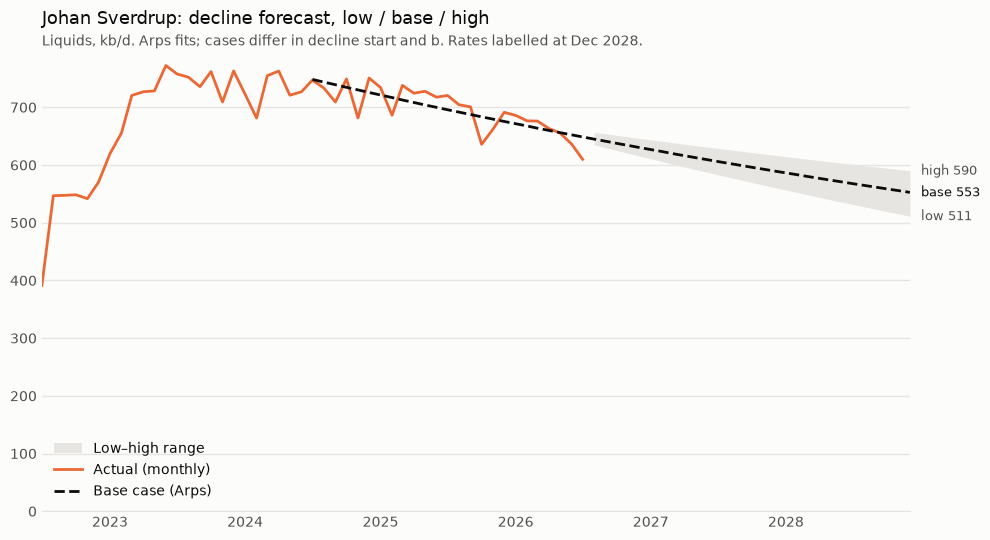

In [33]:
# Same chart style as step 4
SURFACE, TEXT_PRIMARY, TEXT_SECONDARY, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
SVERDRUP_COLOR, RANGE_FILL = "#eb6834", "#e6e5e1"

history = sverdrup["2022-07-01":]
# Base-case curve drawn from its own decline start, so you can judge the fit against the data
base_curve = arps_forecast(
    sverdrup_fits.loc["base"],
    pd.date_range(SVERDRUP_CASES["base"]["decline_start"], "2028-12-01", freq="MS"),
)

fig, ax = plt.subplots(figsize=(10, 5.5), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
ax.fill_between(sverdrup_forecast.index, sverdrup_forecast["low"], sverdrup_forecast["high"],
                color=RANGE_FILL, linewidth=0, label="Low–high range")
ax.plot(history.index, history, color=SVERDRUP_COLOR, linewidth=2, label="Actual (monthly)")
ax.plot(base_curve.index, base_curve, color=TEXT_PRIMARY, linewidth=2, linestyle="--",
        label="Base case (Arps)")

# Label each case at Dec 2028; base in primary ink, low/high in secondary
for case, ink in [("high", TEXT_SECONDARY), ("base", TEXT_PRIMARY), ("low", TEXT_SECONDARY)]:
    rate = sverdrup_forecast[case].iloc[-1]
    ax.annotate(f"{case} {rate:,.0f}", xy=(sverdrup_forecast.index[-1], rate),
                xytext=(8, 0), textcoords="offset points", va="center",
                color=ink, fontsize=9, annotation_clip=False)

ax.set_title("Johan Sverdrup: decline forecast, low / base / high",
             loc="left", color=TEXT_PRIMARY, fontsize=13, pad=22)
ax.text(0, 1.02, "Liquids, kb/d. Arps fits; cases differ in decline start and b. Rates labelled at Dec 2028.",
        transform=ax.transAxes, color=TEXT_SECONDARY, fontsize=10)
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="y", color=GRID, linewidth=1)
ax.set_axisbelow(True)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.tick_params(colors=TEXT_SECONDARY, length=0)
ax.set_ylim(0)
ax.set_xlim(history.index[0], sverdrup_forecast.index[-1])
ax.legend(loc="lower left", frameon=False, labelcolor=TEXT_PRIMARY)

fig.tight_layout()
plt.show()

## Johan Castberg

Too young for a decline fit (online Mar 2025). Model: capacity × uptime on plateau, then exponential decline after an assumed plateau end.

In [34]:
# Engineering judgement (Castberg): online Mar 2025, at capacity from Jul 2025.
# Four months are outages / workovers, not decline (decided in step 4).
CASTBERG_OUTAGE_MONTHS = pd.to_datetime(["2025-11-01", "2025-12-01", "2026-06-01", "2026-07-01"])

castberg = (
    monthly[monthly["field_name"] == "JOHAN CASTBERG"]
    .set_index("production_month")["liquids_kbd"]
)
since_ramp_up = castberg["2025-07-01":]

# Capacity = median of the normal months; uptime = what was actually delivered vs capacity
castberg_capacity = since_ramp_up.drop(CASTBERG_OUTAGE_MONTHS).median()
observed_uptime = since_ramp_up.mean() / castberg_capacity

print(f"Capacity (median of {len(since_ramp_up) - len(CASTBERG_OUTAGE_MONTHS)} normal months): {castberg_capacity:.1f} kb/d")
print(f"Average incl. outages ({len(since_ramp_up)} months): {since_ramp_up.mean():.1f} kb/d")
print(f"Observed uptime: {observed_uptime:.1%}")

Capacity (median of 9 normal months): 204.6 kb/d
Average incl. outages (13 months): 181.9 kb/d
Observed uptime: 88.9%


In [35]:
def plateau_then_decline(months, rate, plateau_end, annual_decline_pct):
    """Flat rate until plateau_end, then exponential decline at annual_decline_pct (effective, %/yr)."""
    t = np.clip(months_between(plateau_end, months).to_numpy(), 0, None)   # 0 for every plateau month
    di = -np.log(1 - annual_decline_pct / 100) / 12                        # effective %/yr -> nominal per month
    return pd.Series(rate * np.exp(-di * t), index=months)


# No decline in the data yet, so plateau end and decline rate are assumptions, not fits
CASTBERG_CASES = {
    "low":  {"uptime": 0.85, "plateau_end": "2027-07-01", "annual_decline_pct": 15},
    "base": {"uptime": 0.92, "plateau_end": "2028-01-01", "annual_decline_pct": 12},
    "high": {"uptime": 0.96, "plateau_end": "2029-01-01", "annual_decline_pct": 12},  # plateau holds through 2028
}

castberg_forecast = pd.DataFrame({
    case: plateau_then_decline(
        forecast_months,
        castberg_capacity * inputs["uptime"],
        inputs["plateau_end"],
        inputs["annual_decline_pct"],
    )
    for case, inputs in CASTBERG_CASES.items()
})

print("Year-end rate, kb/d")
print(castberg_forecast.loc[["2026-12-01", "2027-12-01", "2028-12-01"]].round(0))
print("\nAnnual average, kb/d (2026 = Aug-Dec only)")
print(castberg_forecast.groupby(castberg_forecast.index.year).mean().round(0))

Year-end rate, kb/d
              low   base   high
2026-12-01  174.0  188.0  196.0
2027-12-01  162.0  188.0  196.0
2028-12-01  138.0  167.0  196.0

Annual average, kb/d (2026 = Aug-Dec only)
        low   base   high
2026  174.0  188.0  196.0
2027  171.0  188.0  196.0
2028  149.0  178.0  196.0


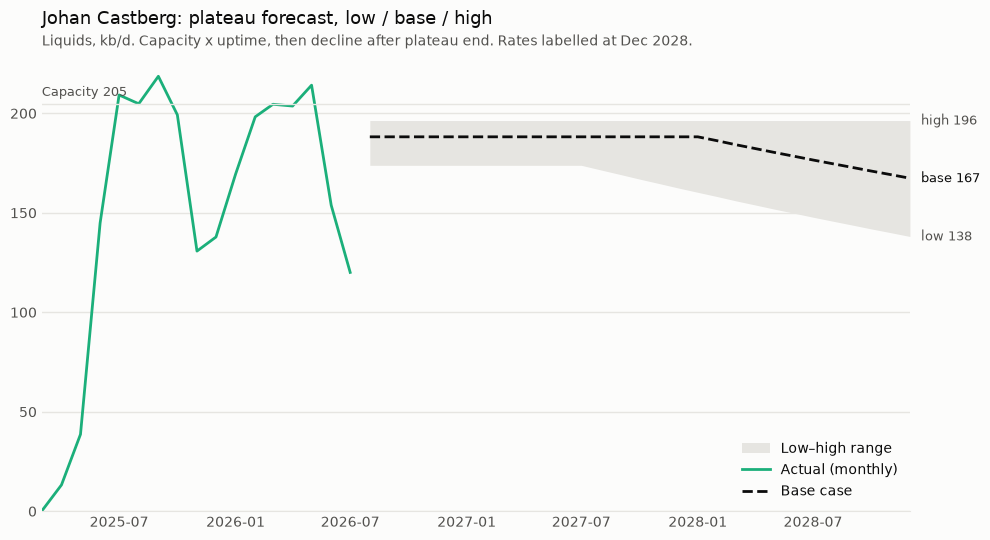

In [36]:
CASTBERG_COLOR = "#1baf7a"   # "ramping up / at peak" color from step 4

history = castberg[castberg.cumsum() > 0]   # from first production
fig, ax = plt.subplots(figsize=(10, 5.5), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
ax.fill_between(castberg_forecast.index, castberg_forecast["low"], castberg_forecast["high"],
                color=RANGE_FILL, linewidth=0, label="Low–high range")
ax.plot(history.index, history, color=CASTBERG_COLOR, linewidth=2, label="Actual (monthly)")
ax.plot(castberg_forecast.index, castberg_forecast["base"], color=TEXT_PRIMARY, linewidth=2,
        linestyle="--", label="Base case")
ax.axhline(castberg_capacity, color=GRID, linewidth=1)
ax.annotate(f"Capacity {castberg_capacity:,.0f}", xy=(history.index[0], castberg_capacity),
            xytext=(0, 6), textcoords="offset points", color=TEXT_SECONDARY, fontsize=9)

# Label each case at Dec 2028; base in primary ink, low/high in secondary
for case, ink in [("high", TEXT_SECONDARY), ("base", TEXT_PRIMARY), ("low", TEXT_SECONDARY)]:
    rate = castberg_forecast[case].iloc[-1]
    ax.annotate(f"{case} {rate:,.0f}", xy=(castberg_forecast.index[-1], rate),
                xytext=(8, 0), textcoords="offset points", va="center",
                color=ink, fontsize=9, annotation_clip=False)

ax.set_title("Johan Castberg: plateau forecast, low / base / high",
             loc="left", color=TEXT_PRIMARY, fontsize=13, pad=22)
ax.text(0, 1.02, "Liquids, kb/d. Capacity x uptime, then decline after plateau end. Rates labelled at Dec 2028.",
        transform=ax.transAxes, color=TEXT_SECONDARY, fontsize=10)
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="y", color=GRID, linewidth=1)
ax.set_axisbelow(True)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.tick_params(colors=TEXT_SECONDARY, length=0)
ax.set_ylim(0)
ax.set_xlim(history.index[0], castberg_forecast.index[-1])
ax.legend(loc="lower right", frameon=False, labelcolor=TEXT_PRIMARY)

fig.tight_layout()
plt.show()

## All other fields and the national total

- **Mature** (declining, ~83 fields): too noisy to fit one by one, so their summed production gets one Arps curve (the "base decline").
- **Young / redeveloped**: young fields plus old fields rising again after redevelopment (e.g. Balder X). Same plateau model as Castberg.
- **National** = Sverdrup + Castberg + mature + young / redeveloped.

In [37]:
# Stages from step 4 (saved to MySQL there) and the field x month liquids table
field_stage = pd.read_sql(
    text("SELECT * FROM field_stage"), db, index_col="field_name", parse_dates=["peak_month"]
)
liquids_by_field = (
    monthly
    .pivot_table(index="production_month", columns="field_name", values="liquids_kbd", fill_value=0)
    .asfreq("MS", fill_value=0)
)
rolling_12m = liquids_by_field.rolling(12).mean()

# Change over the last year: latest 12 months vs the 12 months before
field_stage["previous_12m_kbd"] = rolling_12m.iloc[-13]
field_stage["growth_kbd"] = field_stage["current_kbd"] - field_stage["previous_12m_kbd"]
field_stage["growth_pct"] = field_stage["growth_kbd"] / field_stage["previous_12m_kbd"] * 100

MODELLED_INDIVIDUALLY = ["JOHAN SVERDRUP", "JOHAN CASTBERG"]
is_declining = field_stage["stage"] == "declining"
# Redeveloped: far below the all-time peak, but clearly rising again (e.g. Balder X)
is_redeveloped = is_declining & (field_stage["growth_pct"] >= 20) & (field_stage["growth_kbd"] >= 5)
is_young = field_stage["stage"].isin(["plateau", "ramping up / at peak"])

field_stage["forecast_group"] = "not producing"
field_stage.loc[is_declining, "forecast_group"] = "mature"
field_stage.loc[is_redeveloped | is_young, "forecast_group"] = "young / redeveloped"
field_stage.loc[MODELLED_INDIVIDUALLY, "forecast_group"] = "individual"

field_stage.groupby("forecast_group").agg(
    n_fields=("current_kbd", "size"),
    liquids_kbd=("current_kbd", "sum"),
)

,n_fields,liquids_kbd
forecast_group,,
individual,2,846.054124
mature,83,894.091590
not producing,39,0.000000
young / redeveloped,12,360.335644


In [38]:
# All mature fields summed into one series, fitted with one Arps curve
mature_fields = field_stage.index[field_stage["forecast_group"] == "mature"]
mature_total = liquids_by_field[mature_fields].sum(axis=1)

# Cases backed by the backtest (06_backtest): a 3-year fit window was unbiased,
# a 5-year window ran 5-6% too high at every cutoff.
MATURE_BASE_FIT_START = "2023-08-01"   # last 3 years
MATURE_HIGH_FIT_START = "2021-08-01"   # last 5 years: historically an upper bound
MATURE_LOW_HAIRCUT = 0.05              # backtest error after 24 months was ~5%

mature_fits = pd.DataFrame({
    "base": fit_arps(mature_total[MATURE_BASE_FIT_START:], MATURE_BASE_FIT_START, b=0.01),
    "high": fit_arps(mature_total[MATURE_HIGH_FIT_START:], MATURE_HIGH_FIT_START, b=0.01),
}).T

# Low case: base minus a haircut that grows to 5% over 24 months, like the backtest error
months_ahead = np.arange(1, len(forecast_months) + 1)
low_haircut = np.minimum(months_ahead / 24, 1) * MATURE_LOW_HAIRCUT

mature_base = arps_forecast(mature_fits.loc["base"], forecast_months)
mature_forecast = pd.DataFrame({
    "low": mature_base * (1 - low_haircut),
    "base": mature_base,
    "high": arps_forecast(mature_fits.loc["high"], forecast_months),
})

print("Mature group, annual average kb/d (2026 = Aug-Dec only)")
print(mature_forecast.groupby(mature_forecast.index.year).mean().round(0))
mature_fits


Mature group, annual average kb/d (2026 = Aug-Dec only)
        low   base   high
2026  826.0  831.0  842.0
2027  754.0  772.0  787.0
2028  663.0  696.0  714.0


,decline_start,qi,di,b,r_squared,n_months,annual_decline_pct
base,2023-08-01,1156.993435,0.008726,0.01,0.640129,36,9.936964
high,2021-08-01,1389.663432,0.008098,0.01,0.824311,60,9.255589


In [39]:
other_fields = field_stage.index[field_stage["forecast_group"] == "young / redeveloped"]

# Normal rate today: median of the last 6 months with production (one outage month can't drag it down)
last_6_months = liquids_by_field[other_fields].iloc[-6:]
other_rate = last_6_months.where(last_6_months > 0).median()

# Same plateau model as Castberg; small tie-backs get shorter plateaus
OTHER_CASES = {
    "low":  {"uptime": 0.85, "plateau_end": "2027-01-01", "annual_decline_pct": 15},
    "base": {"uptime": 0.92, "plateau_end": "2027-07-01", "annual_decline_pct": 12},
    "high": {"uptime": 0.96, "plateau_end": "2028-01-01", "annual_decline_pct": 10},
}
other_forecast = pd.DataFrame({
    case: plateau_then_decline(
        forecast_months,
        other_rate.sum() * inputs["uptime"],
        inputs["plateau_end"],
        inputs["annual_decline_pct"],
    )
    for case, inputs in OTHER_CASES.items()
})

print(f"Young / redeveloped: {len(other_fields)} fields, normal rate {other_rate.sum():,.1f} kb/d")
print(other_forecast.groupby(other_forecast.index.year).mean().round(0))
other_rate.sort_values(ascending=False).round(1)

Young / redeveloped: 12 fields, normal rate 416.1 kb/d
        low   base   high
2026  354.0  383.0  399.0
2027  329.0  378.0  399.0
2028  279.0  339.0  381.0


field_name
BALDER         75.7
BREIDABLIKK    68.6
ÅSGARD         58.2
VERDANDE       41.4
HALTEN ØST     35.5
SOLVEIG        26.8
NOVA           26.3
NJORD          23.0
VIGDIS         19.7
MARIA          19.7
SYMRA          14.8
EIRIN           6.3
dtype: float64

In [40]:
# National forecast = sum of the four parts, month by month and case by case
national_forecast = sverdrup_forecast + castberg_forecast + mature_forecast + other_forecast
national_actual = liquids_by_field.sum(axis=1)

# Annual averages; 2026 combines actual Jan-Jul with forecast Aug-Dec
annual = national_forecast.groupby(national_forecast.index.year).sum()
annual.loc[2026] += national_actual["2026"].sum()
annual = annual / 12   # sum of 12 monthly rates / 12 = annual average kb/d

actual_recent = national_actual["2023":"2025"]
print("Actual, annual average kb/d:")
print(actual_recent.groupby(actual_recent.index.year).mean().round(0).to_string())
print("\nForecast, annual average kb/d:")
annual.round(0)

Actual, annual average kb/d:
production_month
2023    2020.0
2024    2000.0
2025    2044.0

Forecast, annual average kb/d:


,low,base,high
2026,2040.0,2066.0,2086.0
2027,1839.0,1946.0,2013.0
2028,1625.0,1781.0,1894.0


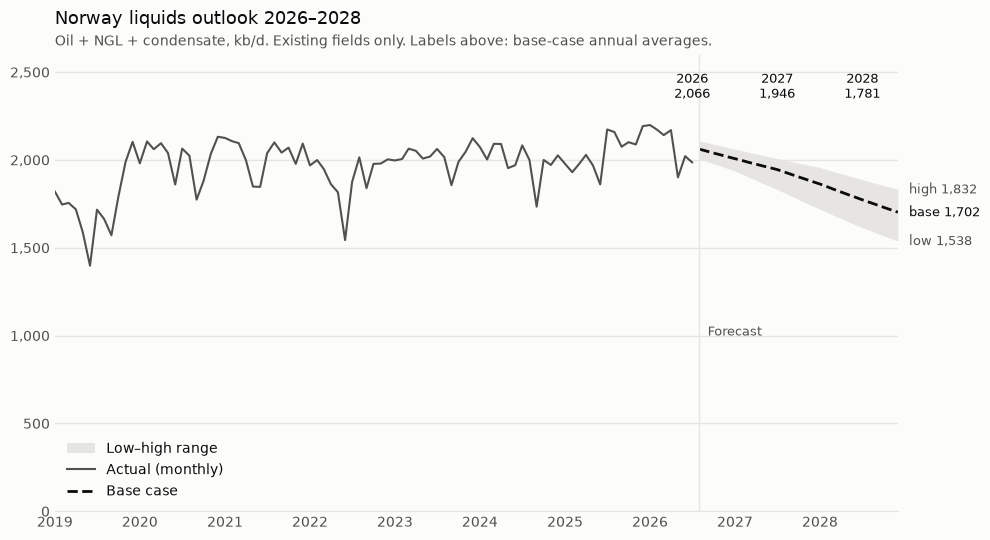

In [41]:
# National outlook: actual monthly liquids, then the three cases
FORECAST_START = forecast_months[0]
actual = national_actual["2019-01-01":]

fig, ax = plt.subplots(figsize=(10, 5.5), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
ax.fill_between(national_forecast.index, national_forecast["low"], national_forecast["high"],
                color=RANGE_FILL, linewidth=0, label="Low–high range")
ax.plot(actual.index, actual, color=TEXT_SECONDARY, linewidth=1.5, label="Actual (monthly)")
ax.plot(national_forecast.index, national_forecast["base"], color=TEXT_PRIMARY, linewidth=2,
        linestyle="--", label="Base case")
ax.axvline(FORECAST_START, color=GRID, linewidth=1)
ax.annotate("Forecast", xy=(FORECAST_START, 1000), xytext=(6, 0), textcoords="offset points",
            color=TEXT_SECONDARY, fontsize=9)

# Annual average of the base case above each forecast year
for year in [2026, 2027, 2028]:
    ax.annotate(f"{year}\n{annual.loc[year, 'base']:,.0f}", xy=(pd.Timestamp(f"{year}-07-01"), 2330),
                ha="center", va="bottom", color=TEXT_PRIMARY, fontsize=9)

# Label each case at Dec 2028
for case, ink in [("high", TEXT_SECONDARY), ("base", TEXT_PRIMARY), ("low", TEXT_SECONDARY)]:
    rate = national_forecast[case].iloc[-1]
    ax.annotate(f"{case} {rate:,.0f}", xy=(national_forecast.index[-1], rate),
                xytext=(8, 0), textcoords="offset points", va="center",
                color=ink, fontsize=9, annotation_clip=False)

ax.set_title("Norway liquids outlook 2026–2028", loc="left", color=TEXT_PRIMARY, fontsize=13, pad=22)
ax.text(0, 1.02, "Oil + NGL + condensate, kb/d. Existing fields only. Labels above: base-case annual averages.",
        transform=ax.transAxes, color=TEXT_SECONDARY, fontsize=10)
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="y", color=GRID, linewidth=1)
ax.set_axisbelow(True)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.tick_params(colors=TEXT_SECONDARY, length=0)
ax.set_ylim(0, 2600)
ax.set_xlim(actual.index[0], national_forecast.index[-1])
ax.legend(loc="lower left", frameon=False, labelcolor=TEXT_PRIMARY)

fig.tight_layout()
plt.show()


In [42]:
# Gold layer: the forecast in long format, one row per month x case x component
FORECAST_COMPONENTS = {
    "Johan Sverdrup": sverdrup_forecast,
    "Johan Castberg": castberg_forecast,
    "Mature fields": mature_forecast,
    "Young / redeveloped": other_forecast,
}

parts = []
for component, forecast in FORECAST_COMPONENTS.items():
    long = (
        forecast
        .rename_axis("production_month")
        .reset_index()
        .melt(id_vars="production_month", var_name="forecast_case", value_name="liquids_kbd")
    )
    long["component"] = component
    parts.append(long)
gold_forecast = pd.concat(parts, ignore_index=True)

gold_forecast.to_sql("gold_liquids_forecast", db, if_exists="replace", index=False)
print(f"Saved {len(gold_forecast)} rows to gold_liquids_forecast")
gold_forecast.head()


Saved 348 rows to gold_liquids_forecast


,production_month,forecast_case,liquids_kbd,component
0,2026-08-01,low,634.870063,Johan Sverdrup
1,2026-09-01,low,629.974165,Johan Sverdrup
2,2026-10-01,low,625.116397,Johan Sverdrup
3,2026-11-01,low,620.296459,Johan Sverdrup
4,2026-12-01,low,615.514054,Johan Sverdrup


In [43]:
create_annual_view = """
CREATE OR REPLACE VIEW gold_liquids_annual AS
WITH
national_actual AS (
    SELECT production_month, SUM(liquids_kbd) AS liquids_kbd
    FROM silver_field_production_rates
    WHERE production_month >= '2023-01-01'
    GROUP BY production_month
),
national_forecast AS (
    SELECT production_month, forecast_case, SUM(liquids_kbd) AS liquids_kbd
    FROM gold_liquids_forecast
    GROUP BY production_month, forecast_case
),
forecast_cases AS (
    SELECT DISTINCT forecast_case FROM gold_liquids_forecast
),
actual_and_forecast AS (
    -- Every case shares the same actual history, then follows its own forecast
    SELECT c.forecast_case, a.production_month, a.liquids_kbd
    FROM national_actual AS a
    CROSS JOIN forecast_cases AS c
    UNION ALL
    SELECT forecast_case, production_month, liquids_kbd
    FROM national_forecast
)
SELECT
    forecast_case,
    YEAR(production_month)    AS year,
    COUNT(*)                  AS n_months,
    AVG(liquids_kbd)          AS liquids_kbd
FROM actual_and_forecast
GROUP BY forecast_case, YEAR(production_month)
"""

with db.begin() as conn:
    conn.execute(text(create_annual_view))
print("View gold_liquids_annual created")


View gold_liquids_annual created


In [44]:
# Query the gold view like any table: one row per case and year
annual_from_mysql = pd.read_sql(text("SELECT * FROM gold_liquids_annual"), db)
print("Months per year:", sorted(annual_from_mysql["n_months"].unique()))
annual_from_mysql.pivot(index="year", columns="forecast_case", values="liquids_kbd").round(0)


Months per year: [np.int64(12)]


forecast_case,base,high,low
year,,,
2023,2020.0,2020.0,2020.0
2024,2000.0,2000.0,2000.0
2025,2044.0,2044.0,2044.0
2026,2066.0,2086.0,2040.0
2027,1946.0,2013.0,1839.0
2028,1781.0,1894.0,1625.0
